In [18]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

In [23]:
df=pd.read_csv('/Users/manojkumar/Documents/repository/python-programming-workbench/house_price_regression_dataset.csv')


In [24]:
x,y=make_blobs(n_samples=1000, centers=5,random_state=42)  ### center =5 means  - generate 5 clusters

In [25]:
df.head()

,Square_Feet,Bedrooms,Bathrooms,House_Age,Price
0,1360,5,1,22,186496
1,1794,3,2,16,250725
2,1630,4,3,7,261345
3,1595,3,3,29,203024
4,2138,3,2,10,306459


In [26]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error  
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score


In [27]:
X = df[["Square_Feet", "Bedrooms", "Bathrooms", "House_Age"]]
y = df["Price"]

In [28]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)


print("\nTraining Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)



Training Data Shape: (96, 4)
Testing Data Shape: (24, 4)


In [29]:
model = LinearRegression()
model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](4,)","[ 119.2 ,14729.79,10929.63,-2257.36]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](4,)","['Square_Feet','Bedrooms','Bathrooms','House_Age']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-2225
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,4
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(4)


In [30]:
y_pred = model.predict(X_test)

In [31]:
print("\nPredicted Values:\n")
print(y_pred[:5])



Predicted Values:

[457931.0386902  370316.20391113 296100.56598051 447381.13482485
 179076.96230957]


In [33]:
# Mean Absolute Error

mae = mean_absolute_error(y_test, y_pred)


# Mean Squared Error
mse = mean_squared_error(y_test, y_pred)


# Root Mean Squared Error
rmse = np.sqrt(mse)


# R2 Score
r2 = r2_score(y_test, y_pred)


print("\nModel Evaluation Metrics")
print("-----------------------------------")
print("Mean Absolute Error :", mae)
print("Mean Squared Error  :", mse)
print("Root Mean Squared Error :", rmse)
print("R2 Score :", r2)



Model Evaluation Metrics
-----------------------------------
Mean Absolute Error : 10806.800866990574
Mean Squared Error  : 156633715.4778166
Root Mean Squared Error : 12515.339207461242
R2 Score : 0.985890757517247


In [34]:
y_pred = model.predict(X_test)

In [35]:
# ------------------------------------------------------------
# STEP 9: MODEL COEFFICIENTS
# ------------------------------------------------------------
## co-efficients are your input features
## intercept is the base value for prediction


print("\nModel Coefficients")
print("-----------------------------------")


feature_names = X.columns


for feature, coef in zip(feature_names, model.coef_):
    print(feature, ":", coef)


print("\nIntercept :", model.intercept_)



Model Coefficients
-----------------------------------
Square_Feet : 119.20068675221361
Bedrooms : 14729.78825266615
Bathrooms : 10929.631464841961
House_Age : -2257.3643704000146

Intercept : -2225.4862794092332


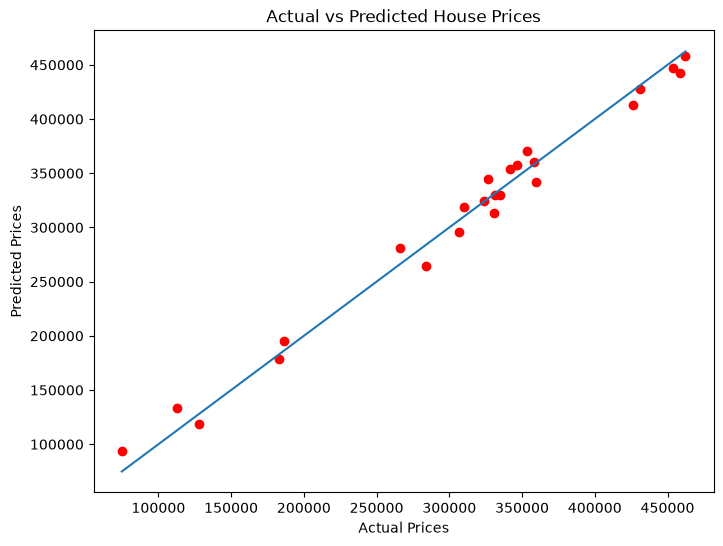

In [36]:
import matplotlib.pyplot as plt


# Scatter plot of Actual vs Predicted values


plt.figure(figsize=(8,6))


plt.scatter(y_test, y_pred,color='red',label='Predicted values')


# Perfect prediction reference line
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()]
)


plt.xlabel("Actual Prices")
plt.ylabel("Predicted Prices")


plt.title("Actual vs Predicted House Prices")


plt.show()
